# Lab : PCA on Wine Quality Dataset (13 features → 2 features)

**Dataset :** [Wine Quality Dataset – Kaggle (yasserh)](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) → `WineQT.csv` (1143 rows, 13 columns)
**Seed :** 77

**Contents**
1. Load data
2. PCA using sklearn (simple code)
3. PCA mathematically (6 steps, NumPy)
4. Hand calculation on 3 samples
5. Answers to the lab questions

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(77)

# Use WineQT.csv if it is in the same folder, else download from Kaggle (Colab), else upload it.
import os, glob
if os.path.exists("WineQT.csv"):
    df = pd.read_csv("WineQT.csv")
else:
    try:
        import kagglehub
        path = kagglehub.dataset_download("yasserh/wine-quality-dataset")
        df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
    except Exception as e:
        print("Kaggle download failed, upload WineQT.csv :", e)
        from google.colab import files
        files.upload()
        df = pd.read_csv("WineQT.csv")

print(df.shape)
df.head()

(1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


All **13 columns** are used as features (11 chemical columns + `quality` + `Id`), as the task asks.
For plotting, wines are grouped into **3 classes** by quality : Low (≤5), Medium (6), High (≥7).

In [2]:
X = df.values                      # 13 features
features = df.columns
classes = pd.cut(df["quality"], bins=[0, 5, 6, 10], labels=["Low", "Medium", "High"])
print("X shape :", X.shape)
print(classes.value_counts())

X shape : (1143, 13)
quality
Low       522
Medium    462
High      159
Name: count, dtype: int64


## 2. PCA using sklearn (simple code)

In [3]:
X_scaled = StandardScaler().fit_transform(X)     # Step 1 : standardize

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)               # 13 -> 2

print("Before :", X_scaled.shape, " After :", X_pca.shape)
print("Explained variance ratio :", pca.explained_variance_ratio_.round(4))
print("Total variance retained  :", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Before : (1143, 13)  After : (1143, 2)
Explained variance ratio : [0.2519 0.1763]
Total variance retained  : 42.82 %


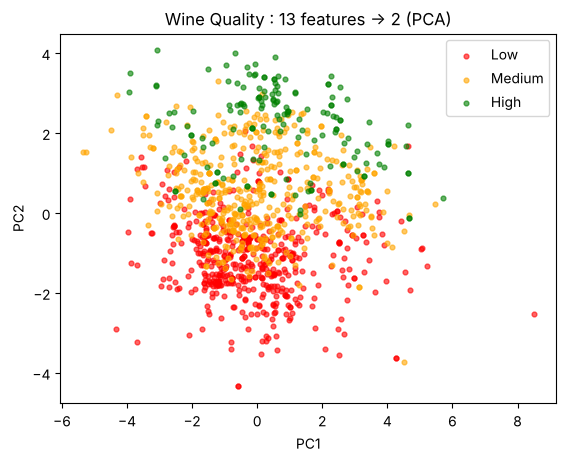

In [4]:
for c, col in zip(["Low", "Medium", "High"], ["red", "orange", "green"]):
    plt.scatter(X_pca[classes == c, 0], X_pca[classes == c, 1], s=12, c=col, label=c, alpha=0.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Wine Quality : 13 features -> 2 (PCA)")
plt.legend(); plt.show()

## 3. PCA mathematically (6 steps)

| Step | Formula |
|---|---|
| 1. Standardize | $z = (x-\mu)/\sigma$ |
| 2. Covariance matrix | $C = \frac{1}{n-1}Z^TZ$ (13 × 13) |
| 3. Eigenvalues & eigenvectors | $Cv = \lambda v$, i.e. $\det(C-\lambda I)=0$ |
| 4. Rank | sort $\lambda_1 \ge \lambda_2 \ge \dots$ |
| 5. Select top 2 | $W = [v_1 \; v_2]$ (13 × 2) |
| 6. Transform | $Y = ZW$ (n × 2) |

In [5]:
# Step 1 : standardize
Z = (X - X.mean(axis=0)) / X.std(axis=0)

# Step 2 : covariance matrix (13 x 13)
C = (Z.T @ Z) / (len(Z) - 1)

# Step 3 : eigenvalues and eigenvectors
eig_vals, eig_vecs = np.linalg.eigh(C)

# Step 4 : rank by decreasing eigenvalue
idx = np.argsort(eig_vals)[::-1]
eig_vals, eig_vecs = eig_vals[idx], eig_vecs[:, idx]

# Step 5 : select top 2 eigenvectors
W = eig_vecs[:, :2]

# Step 6 : transform
Y = Z @ W

print("Eigenvalues :", eig_vals.round(4))
print("Explained variance % :", (eig_vals / eig_vals.sum() * 100).round(2))
print("Y shape :", Y.shape)
print("Same as sklearn (up to sign) :",
      all(np.allclose(abs(Y[:, i]), abs(X_pca[:, i])) for i in range(2)))

Eigenvalues : [3.2779 2.2933 1.7036 1.2172 0.9691 0.9268 0.6281 0.5588 0.4887 0.4075
 0.3109 0.1715 0.0581]
Explained variance % : [25.19 17.63 13.09  9.35  7.45  7.12  4.83  4.29  3.76  3.13  2.39  1.32
  0.45]
Y shape : (1143, 2)
Same as sklearn (up to sign) : True


In [6]:
# Loadings : contribution of each original feature to PC1 and PC2
pd.DataFrame(W, index=features, columns=["PC1", "PC2"]).round(3)

,PC1,PC2
fixed acidity,-0.478,0.032
volatile acidity,0.224,-0.383
citric acid,-0.447,0.194
residual sugar,-0.166,-0.109
chlorides,-0.212,-0.152
free sulfur dioxide,0.056,-0.198
total sulfur dioxide,-0.014,-0.311
density,-0.395,-0.293
pH,0.415,0.024
sulphates,-0.237,0.163


## 4. Hand calculation on 3 samples (for the copy)

1143 × 13 cannot be done by hand, so the same 6 steps are done on 3 rows (Id 0, 1, 3).

**Data**

| | FA | VA | CA | RS | Cl | FSD | TSD | Den | pH | Sul | Alc | Q | Id |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| x₁ | 7.4 | 0.70 | 0.00 | 1.9 | 0.076 | 11 | 34 | 0.9978 | 3.51 | 0.56 | 9.4 | 5 | 0 |
| x₂ | 7.8 | 0.88 | 0.00 | 2.6 | 0.098 | 25 | 67 | 0.9968 | 3.20 | 0.68 | 9.8 | 5 | 1 |
| x₃ | 11.2 | 0.28 | 0.56 | 1.9 | 0.075 | 17 | 60 | 0.9980 | 3.16 | 0.58 | 9.8 | 6 | 3 |

**Step 1 – Standardize** (example FA) : μ = (7.4+7.8+11.2)/3 = 8.8 ; deviations −1.4, −1.0, 2.4 ;
σ = √((1.96+1+5.76)/2) = 2.0881 ; z = −0.6705, −0.4789, 1.1494. Repeat for all 13 columns.

**Step 2 – Covariance** (example) : C(FA,VA) = [(−0.6705)(0.2598) + (−0.4789)(0.8444) + (1.1494)(−1.1043)] / 2 = −0.9239. Diagonal = 1.

**Step 3 – Eigenvalues** : with n = 3, use the small matrix G = ZZᵀ/2 (3 × 3), which has the same non-zero eigenvalues as C.

$$G = \begin{bmatrix} 4.0501 & -2.1279 & -1.9221 \\ -2.1279 & 4.5779 & -2.4499 \\ -1.9221 & -2.4499 & 4.3721 \end{bmatrix}$$

trace = 13, sum of 2×2 minors = 42.0377, det = 0
⇒ λ(λ² − 13λ + 42.0377) = 0 ⇒ λ = (13 ± 0.9215)/2 ⇒ **λ₁ = 6.9608, λ₂ = 6.0392**, rest 0.

Eigenvectors of G : u₁ = (0.1611, −0.7737, 0.6127), u₂ = (0.8004, −0.2607, −0.5397).
Eigenvectors of C : v = Zᵀu / √(2λ).

**Step 4 – Rank** : PC1 = 6.9608/13 = 53.54 %, PC2 = 6.0392/13 = 46.46 %.

**Step 5 – Select** : W = [v₁ v₂] (13 × 2).

**Step 6 – Transform** : Y = ZW = √(2λ)·u

| Sample | PC1 | PC2 |
|---|---|---|
| x₁ | 0.601 | 2.782 |
| x₂ | −2.887 | −0.906 |
| x₃ | 2.286 | −1.876 |

13 features → 2 features. ✔ (verified by the code below; signs may flip, which is still correct)

In [7]:
S = np.array([[7.4, 0.70, 0.00, 1.9, 0.076, 11, 34, 0.9978, 3.51, 0.56, 9.4, 5, 0],
              [7.8, 0.88, 0.00, 2.6, 0.098, 25, 67, 0.9968, 3.20, 0.68, 9.8, 5, 1],
              [11.2, 0.28, 0.56, 1.9, 0.075, 17, 60, 0.9980, 3.16, 0.58, 9.8, 6, 3]])

Zs = (S - S.mean(axis=0)) / S.std(axis=0, ddof=1)    # Step 1
Cs = Zs.T @ Zs / 2                                    # Step 2
vals, vecs = np.linalg.eigh(Cs)                       # Step 3
i = np.argsort(vals)[::-1]; vals, vecs = vals[i], vecs[:, i]   # Step 4
Ws = vecs[:, :2]                                      # Step 5
Ys = Zs @ Ws                                          # Step 6

print("Eigenvalues λ1, λ2 :", vals[:2].round(4))
print("Explained % :", (vals[:2] / vals.sum() * 100).round(2))
print("Projected 3 samples :\n", Ys.round(3))

Eigenvalues λ1, λ2 : [6.9607 6.0393]
Explained % : [53.54 46.46]
Projected 3 samples :
 [[-0.601 -2.782]
 [ 2.887  0.906]
 [-2.286  1.876]]


## 5. Lab Questions

### Question 1 : What happens if we change the number of components? (2 → 3)

In [8]:
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)
print("Shape with 2 components :", X_pca.shape)
print("Shape with 3 components :", X_pca3.shape)
print("Variance retained (2) :", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
print("Variance retained (3) :", round(pca3.explained_variance_ratio_.sum() * 100, 2), "%")

Shape with 2 components : (1143, 2)
Shape with 3 components : (1143, 3)
Variance retained (2) : 42.82 %
Variance retained (3) : 55.91 %


**Answers**
- **Features after reduction :** 3 (PC1, PC2, PC3).
  *How we got it :* We set `n_components=3` and printed `X_pca3.shape`, which shows (1143, **3**). We keep the top 3 eigenvectors, so W becomes 13 × 3 and Y = ZW has 3 columns.
- **Do samples change?** No. The number of rows stays 1143.
  *How we got it :* Both shapes start with 1143. Y = Z·W is (1143 × 13)·(13 × k) = 1143 × k, so only the columns change, never the rows.
- **Variance retained :** It **increases**, from 42.82 % to **55.91 %**.
  *How we got it :* The printed "Variance retained (3)" is higher than "(2)". It equals (λ₁+λ₂+λ₃)/Σλ instead of (λ₁+λ₂)/Σλ, and since λ₃ > 0 it can only go up. PC1 and PC2 stay exactly the same.

### Question 2 : What happens if standardization is removed?

In [9]:
pca_raw = PCA(n_components=2).fit(X)        # X instead of X_scaled
print("With standardization    :", pca.explained_variance_ratio_.round(4))
print("Without standardization :", pca_raw.explained_variance_ratio_.round(4))
print("\nVariance of each raw feature :")
print(df.var().sort_values(ascending=False).round(3))

With standardization    : [0.2519 0.1763]
Without standardization : [0.9946 0.0051]

Variance of each raw feature :
Id                      215293.324
total sulfur dioxide      1074.668
free sulfur dioxide        105.072
fixed acidity                3.054
residual sugar               1.839
alcohol                      1.171
quality                      0.649
citric acid                  0.039
volatile acidity             0.032
sulphates                    0.029
pH                           0.025
chlorides                    0.002
density                      0.000
dtype: float64


**Answers**
- **Does the explained variance ratio change?** Yes, a lot. It goes from [0.2519, 0.1763] to **[0.9946, 0.0051]**, so without scaling PC1 alone explains almost all the variance.
  *How we got it :* We fitted PCA on raw `X` instead of `X_scaled` and printed both ratios side by side. The raw PC1 ratio is close to 1.0, while the scaled one is much smaller.
- **Why do large-scale features dominate?** PCA maximises variance, and variance depends on units. The first components simply point along the largest columns, so the result reflects measurement scale, not real structure.
  *How we got it :* `df.var()` shows `Id` and the sulfur dioxide columns have variances in the hundreds or thousands, while `density` and `chlorides` are near 0. The covariance matrix's largest eigenvalue then comes almost entirely from these big columns.
- **Is standardization always necessary?** Not always. It is needed when features are in **different units or scales**, as here. If all features are already in the same unit and scale (for example, pixel intensities 0 to 255), PCA can be applied without standardizing.
  *How we got it :* Standardization is z = (x − μ)/σ, which gives every feature variance 1. That only matters when the variances are unequal because of units. If the units are already equal, there is nothing to fix.

### Question 3 : What happens if we retain more components? (1, 2, 3, 5, 10)

 1 components -> cumulative variance = 25.19 %
 2 components -> cumulative variance = 42.82 %
 3 components -> cumulative variance = 55.91 %
 5 components -> cumulative variance = 72.71 %
10 components -> cumulative variance = 95.85 %

Components needed for at least 90% variance : 9


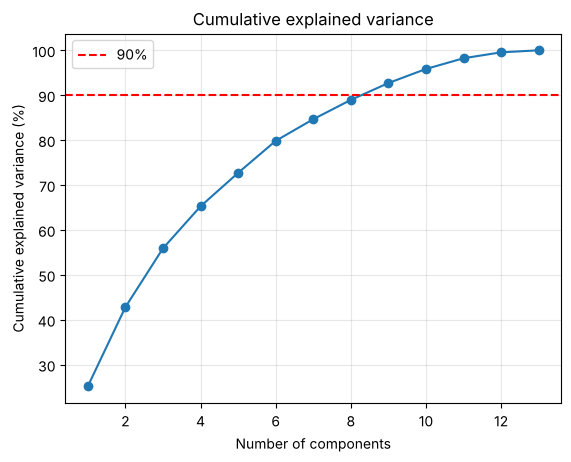

In [10]:
for k in [1, 2, 3, 5, 10]:
    p = PCA(n_components=k).fit(X_scaled)
    print(f"{k:2d} components -> cumulative variance = {p.explained_variance_ratio_.sum()*100:.2f} %")

full = PCA().fit(X_scaled)
cum = np.cumsum(full.explained_variance_ratio_)
k90 = np.argmax(cum >= 0.90) + 1
print("\nComponents needed for at least 90% variance :", k90)

plt.plot(range(1, 14), cum * 100, marker="o")
plt.axhline(90, color="red", ls="--", label="90%")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative explained variance"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Answers**
- **How does cumulative variance change?** It **increases with every extra component** and gets close to 100 % at 13. Each new component adds a smaller amount than the one before, so the curve flattens.
  *How we got it :* The loop printed the cumulative variance for k = 1, 2, 3, 5 and 10, and each value is bigger than the last. The gaps shrink because eigenvalues are sorted largest first (λ₁ ≥ λ₂ ≥ …).
- **Components for ≥ 90 % :** **9 components** (cumulative variance 92.71 %; 8 components give only 88.96 %). That is far more than 2. The chemical features are not strongly correlated, so the information is spread across many components.
  *How we got it :* We fitted PCA with all components, took `np.cumsum` of the ratios, and found the first k where the sum reaches 0.90. On the plot, this is where the blue line crosses the red 90 % line.
- **Is 2 components always best?** No. Two components are good for **visualisation**, because we can plot them, but they keep only part of the variance. For modelling, choose k from the cumulative variance curve (for example 90 % or 95 %) or from the elbow of the scree plot.
  *How we got it :* With k = 2 the printed variance is well below 90 %, so a lot of information is dropped. k should depend on how much variance you need, not be fixed at 2.

### Question 4 : What happens to the visualization?

**Answers** (see the scatter plot in Section 2)
- **Are the classes clearly separated?** No. The Low, Medium and High quality wines **overlap heavily**. Quality depends on small differences across many chemicals, and two components cannot capture that.
  *How we got it :* We coloured each point in the Section 2 scatter plot by its quality class. The red, orange and green points sit mixed together in one cloud instead of forming separate groups.
- **What information is lost (13 → 2)?** **57.18 %** of the variance (only 42.82 % is kept). Finer differences between wines, which may matter for predicting quality, are thrown away.
  *How we got it :* Section 2 printed the total variance kept by PC1 + PC2. Lost information = 100 % − that value, which is exactly the variance in PC3 to PC13 (λ₃ + … + λ₁₃) that we dropped.
- **Does PCA use class labels?** No. PCA is **unsupervised**: it uses only X and the variance between features, never the target. (In this 13-feature setup, `quality` is one of the inputs, so PCA treats it as just another number, not as a label.)
  *How we got it :* In the code, PCA was only ever given `fit_transform(X_scaled)`, never `y`. Mathematically it only uses C = ZᵀZ/(n−1), which has no labels in it. The class colours were added after PCA, only for the plot.

### Question 5 : Does PCA select existing features?

In [11]:
print("Original columns :", list(features))
print("\nPC1 = linear combination of ALL 13 features :")
print(pd.Series(pca.components_[0], index=features).round(3))

Original columns : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

PC1 = linear combination of ALL 13 features :
fixed acidity           0.478
volatile acidity       -0.224
citric acid             0.447
residual sugar          0.166
chlorides               0.212
free sulfur dioxide    -0.056
total sulfur dioxide    0.014
density                 0.395
pH                     -0.415
sulphates               0.237
alcohol                -0.114
quality                 0.079
Id                     -0.207
dtype: float64


**Answers**
- **Are PC1 and PC2 original columns?** No. Each PC is a **new feature**, built as a weighted sum of all 13 original columns:
  PC1 = w₁·(fixed acidity) + w₂·(volatile acidity) + … + w₁₃·(Id). The weights are the eigenvector v₁.
  *How we got it :* We printed `pca.components_[0]`, which has 13 weights, one per column, and most of them are non-zero. So PC1 mixes all the columns. It is not any single column; it is the 13 values of v₁ from Step 3.
- **Feature selection vs feature extraction :**

| Feature Selection | Feature Extraction |
|---|---|
| Keeps a **subset of the original features** | Creates **new features** from the original ones |
| Features keep their meaning (e.g. "alcohol") | New features are combinations, so they are harder to interpret |
| e.g. filter methods, RFE, Lasso | e.g. PCA, LDA, autoencoders |

- **Why is PCA feature extraction?** It does not pick any original column. It **transforms** the data into new axes (the eigenvectors of the covariance matrix), and each new axis mixes information from all features.
  *How we got it :* Step 6 computes Y = Z·W, which multiplies the data by the eigenvector weights. That calculation creates new values, rather than copying any column from the original data.

## Conclusion
- The 13 features of the Wine Quality dataset were reduced to 2 principal components (42.82 % variance kept), using both sklearn and the 6-step mathematical method. The two give the same result.
- Standardization is essential here because the features are on different scales.
- Two components are good for visualisation but keep only part of the variance. 9 components are needed to reach 90 %.